[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DaTrollMon/schutz-gr-solutions-3rd/blob/main/Ch.1/Problem_1.19.ipynb)

# Chapter 1, Problem 19 — the Lorentz transformation as a hyperbolic rotation

**Problem (paraphrased).**
- **(a)** Using the velocity parameter of Problem 18 ($v = \tanh u$), show that the Lorentz transformation Eq. (1.12) can be written
$$
\bar t = t\cosh u - x\sinh u,\quad \bar x = -t\sinh u + x\cosh u,\quad \bar y = y,\quad \bar z = z.
$$
- **(b)** Use $\cosh^2u - \sinh^2u = 1$ to show the invariance of the interval from these equations.
- **(c)** Draw as many parallels as you can between spacetime geometry and ordinary 2D Euclidean geometry, where the analogue of the Lorentz transformation is the rotation $\bar x = x\cos\theta + y\sin\theta$, $\bar y = -x\sin\theta + y\cos\theta$. What is the analogue of the interval? Of the invariant hyperbolae?

In [1]:
# --- setup: shared code for Colab / Codespaces ---
# Locally (uv sync) this does nothing. On Colab it installs the shared `schutz_gr`
# package from GitHub the first time the notebook runs.
try:
    import schutz_gr
except ImportError:
    %pip install -q "git+https://github.com/DaTrollMon/schutz-gr-solutions-3rd"
    import schutz_gr

## (a) $\gamma = \cosh u$, $\gamma v = \sinh u$

With $v = \tanh u$:
$$
1 - v^2 = 1 - \tanh^2u = \frac{\cosh^2u - \sinh^2u}{\cosh^2u} = \frac{1}{\cosh^2u}.
$$
Since $\cosh u > 0$,
$$
\gamma = \frac{1}{\sqrt{1 - v^2}} = \cosh u,\qquad \gamma v = \cosh u\cdot\frac{\sinh u}{\cosh u} = \sinh u .
$$
Substitute into Eq. (1.12), $\bar t = \gamma t - \gamma v x$ and $\bar x = -\gamma v t + \gamma x$:
$$
\boxed{\bar t = t\cosh u - x\sinh u,\qquad \bar x = -t\sinh u + x\cosh u,\qquad \bar y = y,\qquad \bar z = z}
$$

## (b) Invariance of the interval

Work with differences (the transformation is linear). Compute each square:
$$
\begin{aligned}
(\Delta\bar t)^2 &= \Delta t^2\cosh^2u - 2\,\Delta t\,\Delta x\cosh u\sinh u + \Delta x^2\sinh^2u,\\
(\Delta\bar x)^2 &= \Delta t^2\sinh^2u - 2\,\Delta t\,\Delta x\sinh u\cosh u + \Delta x^2\cosh^2u.
\end{aligned}
$$
Subtract — the cross terms cancel:
$$
-(\Delta\bar t)^2 + (\Delta\bar x)^2 = -\Delta t^2(\cosh^2u - \sinh^2u) + \Delta x^2(\cosh^2u - \sinh^2u) = -\Delta t^2 + \Delta x^2.
$$
Adding $(\Delta\bar y)^2 + (\Delta\bar z)^2 = (\Delta y)^2 + (\Delta z)^2$:
$$
\boxed{\Delta\bar s^2 = \Delta s^2}
$$
The identity $\cosh^2 - \sinh^2 = 1$ does all the work, just as $\cos^2 + \sin^2 = 1$ makes rotations preserve distance.

In [2]:
import sympy as sp
u, t, x, v = sp.symbols("u t x v", real=True)
tb = t*sp.cosh(u) - x*sp.sinh(u)
xb = -t*sp.sinh(u) + x*sp.cosh(u)
print("−t̄² + x̄² =", sp.simplify(-tb**2 + xb**2))
g = 1/sp.sqrt(1 - v**2)
print("cosh(atanh v) − γ =", sp.simplify(sp.cosh(sp.atanh(v)) - g),
      "   sinh(atanh v) − γv =", sp.simplify(sp.sinh(sp.atanh(v)) - g*v))

−t̄² + x̄² = -t**2 + x**2
cosh(atanh v) − γ = 0    sinh(atanh v) − γv = 0


## (c) Parallels between Lorentz boosts and Euclidean rotations

| Euclidean plane ($x, y$) | Spacetime plane ($t, x$) |
|---|---|
| rotation by angle $\theta$ | boost by rapidity $u$ |
| $\bar x = x\cos\theta + y\sin\theta$, $\bar y = -x\sin\theta + y\cos\theta$ | $\bar t = t\cosh u - x\sinh u$, $\bar x = -t\sinh u + x\cosh u$ |
| $\cos^2\theta + \sin^2\theta = 1$ | $\cosh^2u - \sinh^2u = 1$ |
| **invariant: squared distance** $\Delta l^2 = \Delta x^2 + \Delta y^2$ | **invariant: interval** $\Delta s^2 = -\Delta t^2 + \Delta x^2$ |
| **circles** $x^2 + y^2 = r^2$: the points a fixed distance from the origin | **invariant hyperbolae** $-t^2 + x^2 = \pm a^2$: the events a fixed interval from the origin |
| a rotation slides points *along* circles | a boost slides events *along* hyperbolae |
| slope of rotated axis: $\tan\theta$ | velocity: $v = \tanh u$ (slope $dx/dt$ of the $\bar t$ axis) |
| rotations compose by adding angles: $\theta_1 + \theta_2$ | boosts (same direction) compose by adding rapidities: $u_1 + u_2$ (Problem 18) |
| tangent-addition formula | velocity-composition law (1.13) = tanh-addition formula |
| unit circle calibrates the length scale on every rotated axis | hyperbolae $\Delta s^2 = \pm1$ calibrate every boosted frame's axes (§1.7, Problem 3f) |
| tangent to a circle is perpendicular to the radius | tangent to a hyperbola at P is the line of simultaneity of the frame whose time axis is OP (§1.7) |
| angle $\theta$ = arc length on the unit circle = 2 × area of the circular sector | rapidity $u$ = 2 × area of the hyperbolic sector of the unit hyperbola $t^2 - x^2 = 1$ |
| "length" of a curve: $\int\sqrt{dx^2 + dy^2}$ | proper time along a world line: $\int\sqrt{dt^2 - dx^2}$ |

**Where the analogy breaks — the signature.**
- $\theta$ is periodic and bounded ($0$ to $2\pi$); $u$ ranges over all of $(-\infty, \infty)$ and is never periodic. You can't boost "all the way round".
- Distance is positive-definite; the interval isn't. It can be positive, negative or zero, giving spacelike, timelike and null separations. The Euclidean plane has no analogue of the **light cone**: no nonzero vector has zero length.
- Rotated axes stay perpendicular (in the Euclidean sense) and turn the same way. Boosted axes "scissor": $\bar t$ and $\bar x$ tilt toward each other, symmetrically about the light cone $t = \pm x$, which is left fixed.
- The triangle inequality reverses for timelike curves: the straight world line between two timelike-separated events has the *longest* proper time (the twin paradox), whereas a straight line is the *shortest* Euclidean path.
- Formally, the substitution $t = i\tau$, $u = -i\theta$ turns one into the other: $\cosh(i\theta) = \cos\theta$, $\sinh(i\theta) = i\sin\theta$, and $-t^2 + x^2 = \tau^2 + x^2$ (the "Wick rotation").

**Direct answers.** The analogue of the interval is the squared distance $\Delta x^2 + \Delta y^2$. The analogue of the invariant hyperbolae is circles centred on the origin.

In [3]:
# rapidity = 2 × area of the hyperbolic sector, just as θ = 2 × area of the circular sector
U = sp.symbols("U", positive=True)
s = sp.symbols("s", real=True)
# sector area from the origin to the point (cosh U, sinh U) on t² − x² = 1:
# area = ½ ∫ (t dx − x dt) along the arc, parametrised by t = cosh s, x = sinh s
area = sp.Rational(1, 2) * sp.integrate(sp.cosh(s)*sp.cosh(s) - sp.sinh(s)*sp.sinh(s), (s, 0, U))
print("hyperbolic sector area =", sp.simplify(area), " ⇒ 2 × area = rapidity U")

hyperbolic sector area = U/2  ⇒ 2 × area = rapidity U


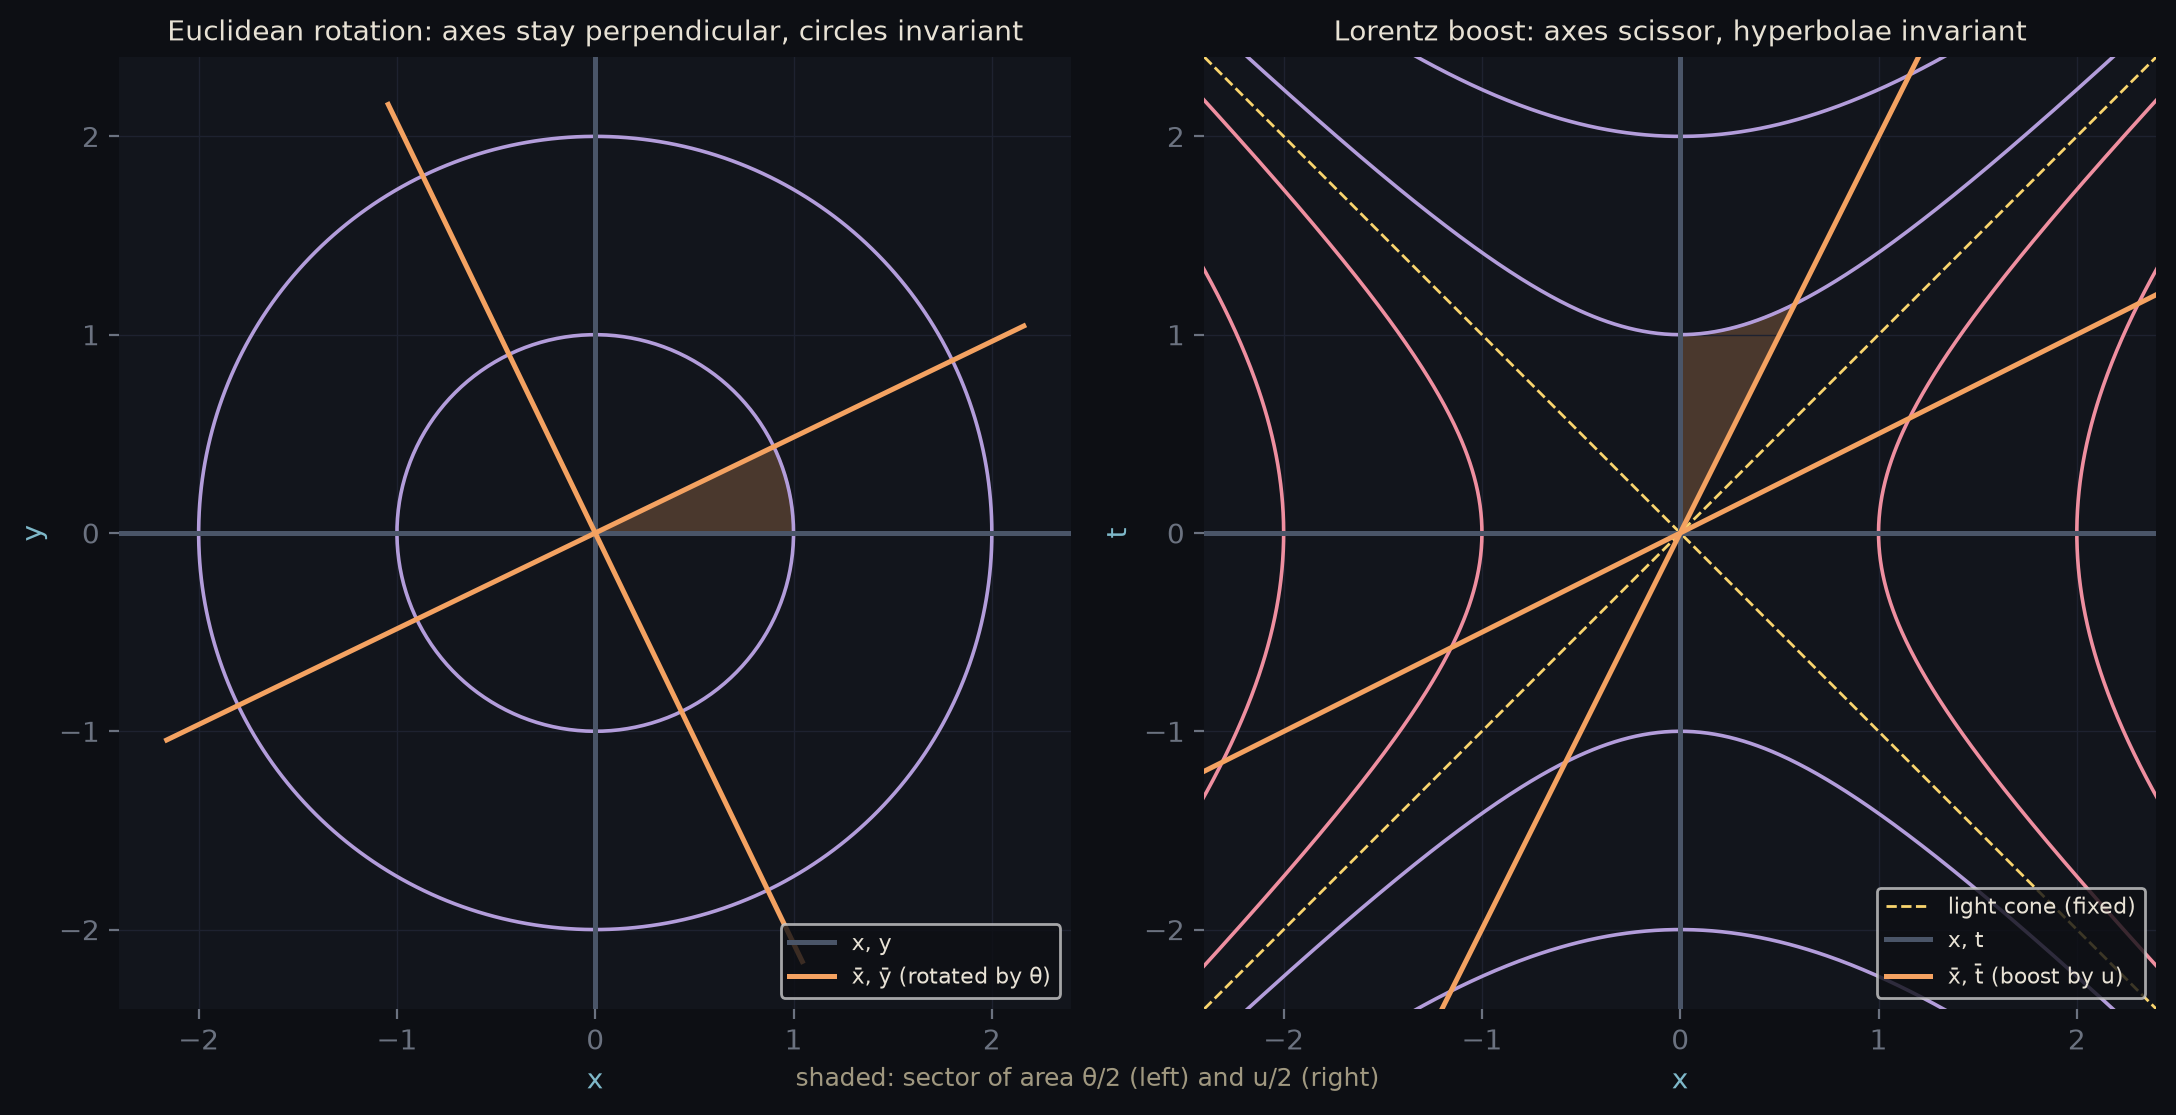

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from schutz_gr.diagrams import COLORS
%config InlineBackend.figure_format = 'retina'

fig, axs = plt.subplots(1, 2, figsize=(11, 5.4)); fig.patch.set_facecolor(COLORS["bg"])
th = 0.45; uu = 0.55
# Euclidean
ax = axs[0]
phi = np.linspace(0, 2*np.pi, 300)
for r in (1, 2): ax.plot(r*np.cos(phi), r*np.sin(phi), color=COLORS["violet"], lw=1.3)
for k, (c, lab) in enumerate(((COLORS["axis"], "x, y"), (COLORS["amber"], "x̄, ȳ (rotated by θ)"))):
    a = 0 if k == 0 else th
    ax.plot([-2.4*np.cos(a), 2.4*np.cos(a)], [-2.4*np.sin(a), 2.4*np.sin(a)], color=c, lw=1.8, label=lab)
    ax.plot([2.4*np.sin(a), -2.4*np.sin(a)], [-2.4*np.cos(a), 2.4*np.cos(a)], color=c, lw=1.8)
p = np.linspace(0, th, 50); ax.fill(np.r_[0, np.cos(p)], np.r_[0, np.sin(p)], color=COLORS["amber"], alpha=0.25)
ax.set_title("Euclidean rotation: axes stay perpendicular, circles invariant", color=COLORS["text"], fontsize=10)
ax.set_xlabel("x", color=COLORS["teal"]); ax.set_ylabel("y", color=COLORS["teal"])
# Minkowski
ax = axs[1]
X = np.linspace(-2.4, 2.4, 400)
for a in (1, 2):
    ax.plot(X, np.sqrt(X**2 + a**2), color=COLORS["violet"], lw=1.3); ax.plot(X, -np.sqrt(X**2 + a**2), color=COLORS["violet"], lw=1.3)
    T = np.linspace(-2.4, 2.4, 400)
    ax.plot(np.sqrt(T**2 + a**2), T, color=COLORS["rose"], lw=1.3); ax.plot(-np.sqrt(T**2 + a**2), T, color=COLORS["rose"], lw=1.3)
ax.plot(X, X, "--", color=COLORS["gold"], lw=1); ax.plot(X, -X, "--", color=COLORS["gold"], lw=1, label="light cone (fixed)")
vv = np.tanh(uu)
ax.plot([-2.4, 2.4], [0, 0], color=COLORS["axis"], lw=1.8, label="x, t"); ax.plot([0, 0], [-2.4, 2.4], color=COLORS["axis"], lw=1.8)
ax.plot(vv*np.array([-2.4, 2.4]), [-2.4, 2.4], color=COLORS["amber"], lw=1.8, label="x̄, t̄ (boost by u)")
ax.plot([-2.4, 2.4], vv*np.array([-2.4, 2.4]), color=COLORS["amber"], lw=1.8)
s_ = np.linspace(0, uu, 50); ax.fill(np.r_[0, np.sinh(s_)], np.r_[0, np.cosh(s_)], color=COLORS["amber"], alpha=0.25)
ax.set_title("Lorentz boost: axes scissor, hyperbolae invariant", color=COLORS["text"], fontsize=10)
ax.set_xlabel("x", color=COLORS["teal"]); ax.set_ylabel("t", color=COLORS["teal"])
for ax in axs:
    ax.set_xlim(-2.4, 2.4); ax.set_ylim(-2.4, 2.4); ax.set_aspect("equal"); ax.set_facecolor(COLORS["panel"])
    ax.tick_params(colors=COLORS["grey"]); ax.grid(color=COLORS["grid"], lw=0.5)
    for s in ax.spines.values(): s.set_visible(False)
    leg = ax.legend(fontsize=8, loc="lower right"); leg.get_frame().set_facecolor(COLORS["bg"])
    for t_ in leg.get_texts(): t_.set_color(COLORS["text"])
fig.text(0.5, 0.01, "shaded: sector of area θ/2 (left) and u/2 (right)", color=COLORS["muted"], ha="center", fontsize=9)
plt.tight_layout(); plt.show()